<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js11/TG11_TP_244107020211_NURFINKA_LAILASARI_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum - Klasifikasi SVM
**Soal 1:** SVM pada `voice.csv` (split 70:30 dan 80:20; kernel linier, polynomial, RBF).  
**Soal 2:** Klasifikasi siang/malam (data Praktikum 5) dengan SVM kernel RBF, fitur histogram, split 80:20.

Persiapan di Colab: upload `voice.csv` dan zip dataset siang/malam, lalu ekstrak zip-nya.

# Soal 1 - SVM pada voice.csv

## 1.0 Import library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

## 1.1 Load dan inspeksi data

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving voice (1).csv to voice (1) (1).csv


In [ ]:
import glob
csv_path = sorted(glob.glob('voice*.csv'))[0]   # otomatis ambil file voice*.csv yang sudah diupload
print('Membaca file:', csv_path)
df = pd.read_csv(csv_path)
print(df.shape)
df.head()

(3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [ ]:
print(df.isnull().sum().sum(), 'nilai kosong')
print(df.iloc[:, -1].value_counts())

0 nilai kosong
label
male      1584
female    1584
Name: count, dtype: int64


## 1.2 Pisahkan fitur dan label
Kolom terakhir adalah label (male/female).

In [ ]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]
print(X.shape, y.shape)

(3168, 20) (3168,)


## 1.3 Fungsi untuk melatih dan mengevaluasi model
Fitur distandarisasi (StandardScaler) di dalam pipeline, di-fit hanya pada data training agar tidak terjadi kebocoran data.

In [ ]:
def run_experiment(X, y, test_size, kernel, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y)

    model = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    model.fit(X_train, y_train)

    acc_train = accuracy_score(y_train, model.predict(X_train))
    acc_test = accuracy_score(y_test, model.predict(X_test))
    return acc_train, acc_test

## 1.4 Jalankan semua kombinasi (2 split x 3 kernel)

In [ ]:
splits = {'70:30': 0.30, '80:20': 0.20}
kernels = ['linear', 'poly', 'rbf']

hasil = []
for split_name, test_size in splits.items():
    for kernel in kernels:
        acc_train, acc_test = run_experiment(X, y, test_size, kernel)
        hasil.append({'Split': split_name, 'Kernel': kernel,
                      'Akurasi Train': acc_train, 'Akurasi Test': acc_test})

hasil_df = pd.DataFrame(hasil)
hasil_df

,Split,Kernel,Akurasi Train,Akurasi Test
0,70:30,linear,0.972034,0.978970
1,70:30,poly,0.966622,0.960042
2,70:30,rbf,0.983762,0.983176
3,80:20,linear,0.976717,0.974763
4,80:20,poly,0.968035,0.955836
5,80:20,rbf,0.983820,0.982650


## 1.5 Tabulasi performansi (akurasi data testing)

In [ ]:
tabel = hasil_df.pivot(index='Kernel', columns='Split', values='Akurasi Test')
tabel = tabel.loc[kernels]
(tabel * 100).round(2).astype(str) + ' %'

Split,70:30,80:20
Kernel,,
linear,97.9 %,97.48 %
poly,96.0 %,95.58 %
rbf,98.32 %,98.26 %


## 1.6 Visualisasi perbandingan

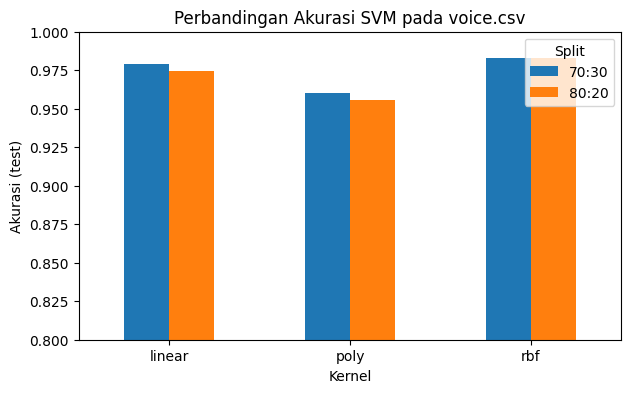

In [ ]:
ax = tabel.plot(kind='bar', figsize=(7, 4), rot=0)
ax.set_ylabel('Akurasi (test)')
ax.set_ylim(0.8, 1.0)
ax.set_title('Perbandingan Akurasi SVM pada voice.csv')
plt.show()

# Soal 2 - Klasifikasi Siang/Malam: SVM RBF + Fitur Histogram (80:20)

## 2.0a Upload dan ekstrak dataset gambar siang/malam
Unduh dataset (zip) dari halaman Praktikum 5, lalu upload di sini. Sel ini hanya perlu dijalankan sekali per sesi Colab.

In [ ]:
from google.colab import files
import zipfile, os

uploaded_img = files.upload()   # pilih file .zip dataset gambar siang/malam

zip_name = list(uploaded_img.keys())[0]
os.makedirs('/content/dataset_img', exist_ok=True)
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content/dataset_img')
print('Berhasil diekstrak dari:', zip_name)

# Cek struktur folder hasil ekstrak
for root, dirs, fs in os.walk('/content/dataset_img'):
    if '__MACOSX' in root:
        continue
    if fs:
        print(root, '->', len(fs), 'file')

Saving images.zip to images.zip
Berhasil diekstrak dari: images.zip
/content/dataset_img/images/training/night -> 120 file
/content/dataset_img/images/training/day -> 120 file
/content/dataset_img/images/test/night -> 80 file
/content/dataset_img/images/test/day -> 80 file


## 2.0 Import library dan lokasi data

In [ ]:
from pathlib import Path
import cv2
import matplotlib.image as mpimg
from sklearn.model_selection import GridSearchCV

# Cari otomatis folder 'training' dan 'test' hasil ekstrak (abaikan folder sampah __MACOSX)
def find_dir(root, name):
    for p in Path(root).rglob(name):
        if p.is_dir() and '__MACOSX' not in p.parts:
            return str(p) + '/'
    return None

train_dir = find_dir('/content/dataset_img', 'training')
test_dir = find_dir('/content/dataset_img', 'test')
print('train_dir:', train_dir)
print('test_dir :', test_dir)

assert train_dir and test_dir, (
    "Folder training/test tidak ditemukan. Jalankan dulu sel upload & ekstrak dataset gambar (2.0a).")

## 2.1 Load seluruh gambar (training + test digabung)
Karena soal meminta rasio 80:20, seluruh gambar digabung lalu dibagi ulang.

In [ ]:
def load_dataset(img_dir):
    img_list = []
    for d in Path(img_dir).glob('*'):
        if not d.is_dir():
            continue
        for file in d.glob('*'):
            if file.suffix.lower() in ['.jpg', '.jpeg', '.png']:   # tidak peka huruf besar/kecil
                img = mpimg.imread(file)
                if img is not None:
                    # pastikan 3 channel RGB dan bertipe uint8 (png bisa float 0-1 / RGBA)
                    if img.dtype != np.uint8:
                        img = (img * 255).astype(np.uint8)
                    if img.ndim == 3 and img.shape[2] == 4:
                        img = img[:, :, :3]
                    img_list.append((img, d.name))
    return img_list

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)
all_img = train_img + test_img
print(f'Gambar training: {len(train_img)} | test: {len(test_img)} | total: {len(all_img)}')
assert len(all_img) > 0, 'Tidak ada gambar terbaca. Cek isi folder dan path pada sel 2.0.'

from collections import Counter
print(Counter(label for _, label in all_img))   # harus berisi 'day' dan 'night'

## 2.2 Pra pengolahan: resize dan encoding label (day = 1, night = 0)

In [ ]:
def preprocess(img_list):
    out = []
    for img, label in img_list:
        std_img = cv2.resize(img, (1100, 600))
        out.append((std_img, 1 if label == 'day' else 0))
    return out

all_std = preprocess(all_img)

## 2.3 Ekstraksi fitur histogram
Histogram HSV (H, S, V), masing-masing 16 bin, dinormalisasi lalu digabung menjadi 48 fitur per gambar.

In [ ]:
def hist_feature(image, bins=16):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    ranges = [(0, 180), (0, 256), (0, 256)]
    feats = []
    for ch, rng in enumerate(ranges):
        h, _ = np.histogram(hsv[:, :, ch], bins=bins, range=rng)
        feats.append(h / h.sum())
    return np.concatenate(feats)

X_hist = np.array([hist_feature(img) for img, _ in all_std])
y_hist = np.array([label for _, label in all_std])
print(X_hist.shape, y_hist.shape)

## 2.4 Split data 80:20

In [ ]:
print('Shape fitur  :', X_hist.shape)
print('Shape label   :', y_hist.shape)
print('Jumlah day/night:', int(y_hist.sum()), '/', int(len(y_hist) - y_hist.sum()))
assert len(X_hist) > 0, 'Data kosong, periksa langkah load dataset (2.1).'

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(
    X_hist, y_hist, test_size=0.20, random_state=42, stratify=y_hist)
print(Xtr.shape, Xte.shape)

## 2.5 Baseline: SVM RBF dengan parameter default

In [ ]:
base = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
base.fit(Xtr, ytr)
acc_base = accuracy_score(yte, base.predict(Xte))
print(f'Akurasi baseline (RBF default): {acc_base:.4f}')

## 2.6 Hyperparameter tuning RBF (GridSearchCV pada data training)

In [ ]:
param_grid = {'svc__C': [0.1, 1, 10, 100],
              'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1]}

pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(Xtr, ytr)

print('Parameter terbaik:', grid.best_params_)
print(f'Akurasi CV terbaik: {grid.best_score_:.4f}')

## 2.7 Evaluasi model terbaik pada data testing

In [ ]:
best = grid.best_estimator_
yfit = best.predict(Xte)
acc_best = accuracy_score(yte, yfit)
print(f'Akurasi test (model tuning): {acc_best:.4f}')

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(yte, yfit, target_names=['night', 'day']))
print(confusion_matrix(yte, yfit))

## 2.8 Catatan performansi

In [ ]:
catatan = pd.DataFrame({
    'Model': ['RBF default', 'RBF + tuning'],
    'Parameter': ['C=1, gamma=scale', str(grid.best_params_)],
    'Akurasi Test': [acc_base, acc_best]})
catatan